# Forecasting net migration with machine learning

**Question:** how well can last year's economic and political indicators, plus recent migration history, forecast a country's net migration one year ahead?

**Data:** World Bank World Development Indicators, 1975 to 2024 (see `data/README.md`).

**Approach:** train on 1997 to 2014, test on 2015 to 2024, and compare every model with a naive forecast that simply repeats last year's value.

This is a revised version of my MSc dissertation analysis (Dublin Business School, 2025). The section at the end lists what changed and why.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", message="IProgress not found")
import shap
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import prep

DATA = ROOT / "data" / "wdi_migration_extract.csv"  # use "wdi_full.csv" after running scripts/download_wdi.py
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

SEED = 42
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": MUTED,
    "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "savefig.dpi": 150,
    "savefig.bbox": "tight", "axes.axisbelow": True,
})
pd.set_option("display.float_format", "{:,.3f}".format)

## 1. Load and check the data

The raw file is a long table (country, year, series, value). Two things need fixing before any modelling:

- **Regional and income-group aggregates** such as "Euro area" or "High income" sit next to real countries. They are sums of those countries, so they are removed.
- **The export stops part-way through the alphabet.** The World Bank download caps at 30,000 rows, so the file ends at Russia (1975 to 1985 only). Countries from Russia onwards (Spain, the UK, the US and others) are missing. `scripts/download_wdi.py` fetches the full set.

In [2]:
long_df = prep.load_long(DATA)
panel = prep.to_panel(long_df)
countries = prep.drop_aggregates(panel)
kept = prep.drop_incomplete_countries(countries)

print(f"Entities in file:            {panel['code'].nunique()}")
print(f"After removing aggregates:   {countries['code'].nunique()}")
print(f"With 40+ years of migration: {kept['code'].nunique()}  (dropped: {sorted(set(countries['code']) - set(kept['code']))})")
print(f"Alphabetical range:          {kept['country'].min()} to {kept['country'].max()}")

Entities in file:            202
After removing aggregates:   162
With 40+ years of migration: 160  (dropped: ['PRK', 'RUS'])
Alphabetical range:          Afghanistan to Romania


### How complete is each indicator?

Poverty rate and remittance cost are mostly empty, so filling them in would mean inventing most of the values. They are left out of the model.

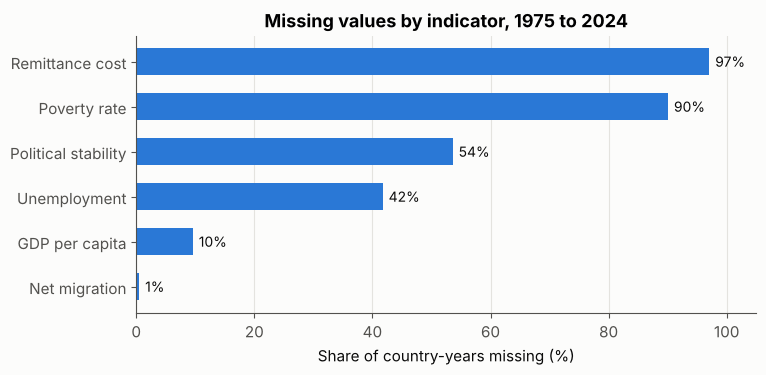

In [3]:
labels = {
    "net_migration": "Net migration", "gdp_per_capita": "GDP per capita",
    "unemployment": "Unemployment", "political_stability": "Political stability",
    "poverty_rate": "Poverty rate", "remittance_cost": "Remittance cost",
}
missing = (kept[list(labels)].isna().mean() * 100).rename(labels).sort_values()

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(missing.index, missing.values, color=BLUE, height=0.6)
for y, v in enumerate(missing.values):
    ax.text(v + 1, y, f"{v:.0f}%", va="center", color=INK, fontsize=10)
ax.set_xlim(0, 105)
ax.set_xlabel("Share of country-years missing (%)")
ax.set_title("Missing values by indicator, 1975 to 2024")
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "missing_values.png")
plt.show()

## 2. Build features

For each country and year *t*, the model gets:

- net migration in *t-1*, *t-2* and *t-3*
- GDP per capita (log scale), unemployment and political stability from *t-1*

Gaps in the indicators are filled with the most recent earlier value for that country, never a later one. Unemployment and political stability only start in the 1990s, so rows before 1997 are dropped.

In [4]:
PREDICTORS = ["gdp_per_capita", "unemployment", "political_stability"]
LAGS = ["net_migration_lag1", "net_migration_lag2", "net_migration_lag3"]
DRIVERS = ["log_gdp_per_capita_prev", "unemployment_prev", "political_stability_prev"]
FEATURES = DRIVERS + LAGS
TARGET = "net_migration"

data = prep.build_dataset(DATA, PREDICTORS)
data = data[data["year"] >= 1997].reset_index(drop=True)

train = data[data["year"] <= 2014]
test = data[data["year"] >= 2015].copy()
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

print(f"Train: {len(train):,} rows, {train['year'].min()} to {train['year'].max()}")
print(f"Test:  {len(test):,} rows, {test['year'].min()} to {test['year'].max()}")
print(f"Countries: {data['code'].nunique()}")
print("\nMissing after forward fill (filled with the training median inside each model):")
print(data[FEATURES].isna().mean().round(3).to_string())

Train: 2,875 rows, 1997 to 2014
Test:  1,535 rows, 2015 to 2024
Countries: 160

Missing after forward fill (filled with the training median inside each model):
log_gdp_per_capita_prev    0.024
unemployment_prev          0.139
political_stability_prev   0.080
net_migration_lag1         0.000
net_migration_lag2         0.000
net_migration_lag3         0.000


## 3. Validation folds for tuning

Tuning uses only the training years, with two rolling folds so that each validation block lies after its training block:

| Fold | Train | Validate |
|---|---|---|
| 1 | 1997 to 2004 | 2005 to 2009 |
| 2 | 1997 to 2009 | 2010 to 2014 |

In [5]:
def year_folds(df, cutoffs=((2004, 2009), (2009, 2014))):
    years = df["year"].to_numpy()
    return [
        (np.where(years <= end_train)[0], np.where((years > end_train) & (years <= end_val))[0])
        for end_train, end_val in cutoffs
    ]

folds = year_folds(train)
for i, (tr, va) in enumerate(folds, 1):
    print(f"Fold {i}: train {len(tr):,} rows, validate {len(va):,} rows")

Fold 1: train 1,279 rows, validate 800 rows
Fold 2: train 2,079 rows, validate 796 rows


## 4. Models

- **Naive:** next year equals this year. Any model worth using has to beat this.
- **Linear regression**
- **Random forest**, tuned on the folds above
- **Support vector regression** (linear kernel), tuned on the folds above
- **Random forest using drivers only:** no migration history, to see how much the economic and political indicators explain on their own

Imputation and scaling sit inside each pipeline, so they are fitted on training data only.

In [6]:
def evaluate(y_true, y_pred, frame):
    by_country = frame.assign(err=np.abs(y_true - y_pred), naive_err=np.abs(y_true - frame["net_migration_lag1"]))
    beats = by_country.groupby("code")[["err", "naive_err"]].mean()
    return {
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "Median abs error": np.median(np.abs(y_true - y_pred)),
        "Countries beating naive": (beats["err"] < beats["naive_err"]).mean(),
    }

predictions = {"Naive (last year)": test["net_migration_lag1"].to_numpy()}

linear = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression())
linear.fit(X_train, y_train)
predictions["Linear regression"] = linear.predict(X_test)

In [7]:
rf_search = GridSearchCV(
    make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)),
    param_grid={
        "randomforestregressor__max_depth": [None, 10, 20],
        "randomforestregressor__min_samples_leaf": [1, 2, 5, 10],
        "randomforestregressor__max_features": [1.0, 0.5],
    },
    cv=folds, scoring="neg_mean_absolute_error", n_jobs=-1,
)
rf_search.fit(X_train, y_train)
rf = rf_search.best_estimator_
predictions["Random forest (tuned)"] = rf.predict(X_test)
print("Best random forest settings:", {k.split("__")[1]: v for k, v in rf_search.best_params_.items()})

Best random forest settings: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 5}


In [8]:
svr_search = GridSearchCV(
    make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), SVR(kernel="linear")),
    param_grid={"svr__C": [100, 1000, 10000], "svr__epsilon": [0.1, 1000]},
    cv=folds, scoring="neg_mean_absolute_error", n_jobs=-1,
)
svr_search.fit(X_train, y_train)
predictions["SVR (linear, tuned)"] = svr_search.best_estimator_.predict(X_test)
print("Best SVR settings:", {k.split("__")[1]: v for k, v in svr_search.best_params_.items()})

Best SVR settings: {'C': 1000, 'epsilon': 0.1}


In [9]:
rf_drivers = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
)
rf_drivers.fit(train[DRIVERS], y_train)
predictions["Random forest, drivers only"] = rf_drivers.predict(test[DRIVERS])

## 5. Results on the 2015 to 2024 test set

In [10]:
results = pd.DataFrame({name: evaluate(y_test.to_numpy(), pred, test) for name, pred in predictions.items()}).T
results.to_csv(FIGURES / "results.csv")
results.style.format({
    "R2": "{:.3f}", "MAE": "{:,.0f}", "RMSE": "{:,.0f}",
    "Median abs error": "{:,.0f}", "Countries beating naive": "{:.0%}",
})

,R2,MAE,RMSE,Median abs error,Countries beating naive
Naive (last year),0.693,"32,530","101,672","2,713",0%
Linear regression,0.742,"33,889","93,240","7,743",32%
Random forest (tuned),0.693,"33,904","101,782","4,793",24%
"SVR (linear, tuned)",0.720,"32,496","97,164","3,694",41%
"Random forest, drivers only",0.060,"73,823","178,013","26,536",7%


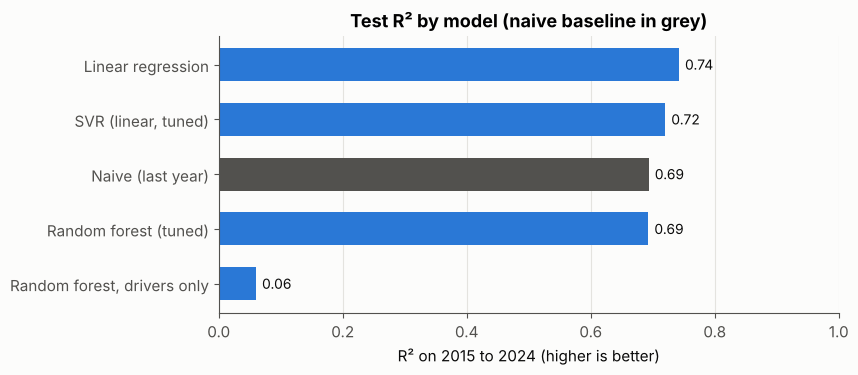

In [11]:
order = results["R2"].sort_values()
colors = [MUTED if "Naive" in name else BLUE for name in order.index]

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(order.index, order.values, color=colors, height=0.6)
for y, v in enumerate(order.values):
    ax.text(v + 0.01, y, f"{v:.2f}", va="center", color=INK, fontsize=10)
ax.set_xlim(0, 1)
ax.set_xlabel("R² on 2015 to 2024 (higher is better)")
ax.set_title("Test R² by model (naive baseline in grey)")
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "model_r2.png")
plt.show()

### What the numbers say

- **Migration has strong momentum.** Repeating last year's value already gives an R² of 0.69.
- **The models add a little on top of that.** Linear regression does best, with an R² of 0.74 and about 8% lower RMSE than the naive forecast. The tuned random forest only matches the baseline.
- **The gain comes from the big swings in large countries.** Country by country, the naive forecast is still more accurate for most of them (see "Countries beating naive"), and its median error is the smallest.
- **Indicators alone explain very little.** Without migration history, the random forest falls to an R² of 0.06.

### Accuracy by year

2020 and 2022 stand out: COVID-19 and the war in Ukraine caused shocks that no model trained on earlier years could see coming.

In [12]:
test["rf_pred"] = predictions["Random forest (tuned)"]
by_year = test.groupby("year").apply(
    lambda g: pd.Series({
        "Naive R2": r2_score(g[TARGET], g["net_migration_lag1"]),
        "Random forest R2": r2_score(g[TARGET], g["rf_pred"]),
    }),
    include_groups=False,
)
by_year

,Naive R2,Random forest R2
year,,
2015,0.845,0.683
2016,0.742,0.721
2017,0.817,0.905
2018,0.894,0.884
2019,0.830,0.711
2020,-0.096,0.359
2021,0.544,0.716
2022,0.470,0.414
2023,0.571,0.691


## 6. Case study: Ireland

The pooled model's forecasts for Ireland, 2015 to 2024. With only ten test years, an R² for a single country is not reliable, so the comparison uses mean absolute error.

Ireland MAE, random forest: 16,895
Ireland MAE, naive:         18,284


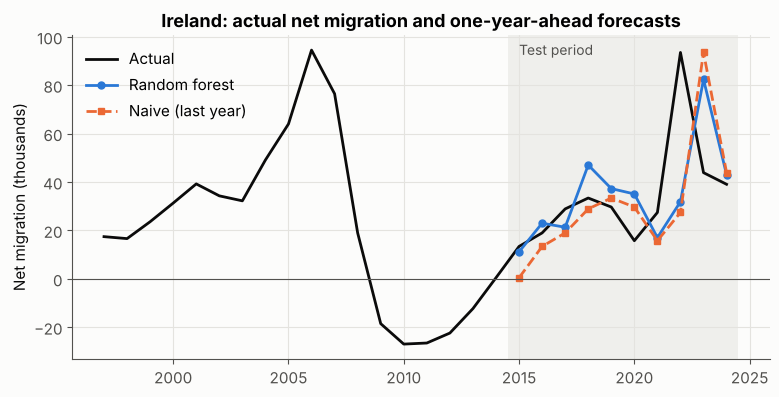

In [13]:
ireland = test[test["code"] == "IRL"]
mae_rf = mean_absolute_error(ireland[TARGET], ireland["rf_pred"])
mae_naive = mean_absolute_error(ireland[TARGET], ireland["net_migration_lag1"])
print(f"Ireland MAE, random forest: {mae_rf:,.0f}")
print(f"Ireland MAE, naive:         {mae_naive:,.0f}")

history = data[(data["code"] == "IRL")]
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(history["year"], history[TARGET] / 1000, color=INK, lw=2, label="Actual")
ax.plot(ireland["year"], ireland["rf_pred"] / 1000, color=BLUE, lw=2, marker="o", ms=5, label="Random forest")
ax.plot(ireland["year"], ireland["net_migration_lag1"] / 1000, color=ORANGE, lw=2, ls="--", marker="s", ms=5, label="Naive (last year)")
ax.axvspan(2014.5, 2024.5, color=GRID, alpha=0.5, lw=0)
ax.text(2015, ax.get_ylim()[1] * 0.92, "Test period", color=MUTED, fontsize=10)
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_ylabel("Net migration (thousands)")
ax.set_title("Ireland: actual net migration and one-year-ahead forecasts")
ax.legend(frameon=False, loc="upper left")
fig.savefig(FIGURES / "ireland_forecast.png")
plt.show()

Both forecasts follow the trend, and the random forest has a slightly lower error than the naive forecast for Ireland. Neither predicts the 2022 jump (about 93,500, driven largely by arrivals from Ukraine), and both then overshoot in 2023 because they lean on the previous year. One-year-ahead forecasts from past data cannot anticipate a shock like that.

## 7. What drives the random forest? (SHAP)

SHAP values show how much each feature pushes a single prediction up or down. They are computed on the test set using the tuned random forest.

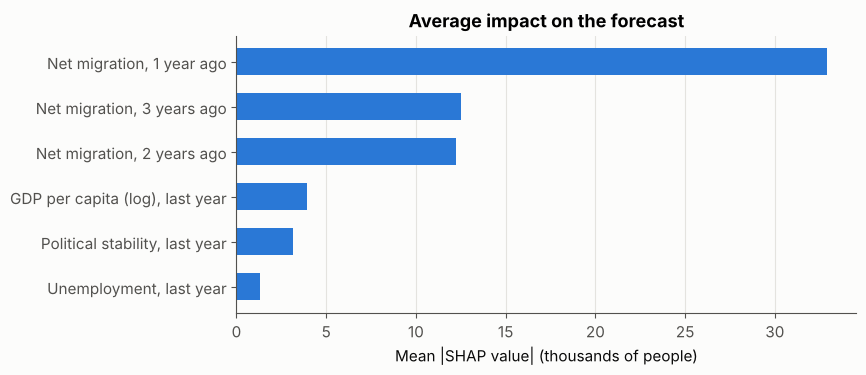

In [14]:
imputer, forest = rf.named_steps["simpleimputer"], rf.named_steps["randomforestregressor"]
X_test_filled = pd.DataFrame(imputer.transform(X_test), columns=FEATURES, index=X_test.index)
shap_values = shap.TreeExplainer(forest).shap_values(X_test_filled)

pretty = {
    "net_migration_lag1": "Net migration, 1 year ago", "net_migration_lag2": "Net migration, 2 years ago",
    "net_migration_lag3": "Net migration, 3 years ago", "log_gdp_per_capita_prev": "GDP per capita (log), last year",
    "unemployment_prev": "Unemployment, last year", "political_stability_prev": "Political stability, last year",
}
importance = pd.Series(np.abs(shap_values).mean(axis=0), index=[pretty[f] for f in FEATURES]).sort_values()

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(importance.index, importance.values / 1000, color=BLUE, height=0.6)
ax.set_xlabel("Mean |SHAP value| (thousands of people)")
ax.set_title("Average impact on the forecast")
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "shap_importance.png")
plt.show()

### Is there a GDP threshold?

The dissertation reported that emigration rises below about $3,000 GDP per capita. The SHAP values for GDP support the direction: below roughly $3,000 the GDP feature pushes forecasts towards net emigration, above it towards net immigration. The change is a gradual slope rather than a sharp cliff.

                            median  count
log_gdp_per_capita_prev                  
< $1k                   -3,960.000    166
$1k to 3k               -1,997.000    251
$3k to 10k                 373.000    480
$10k to 30k              2,066.000    290
> $30k                   4,532.000    348


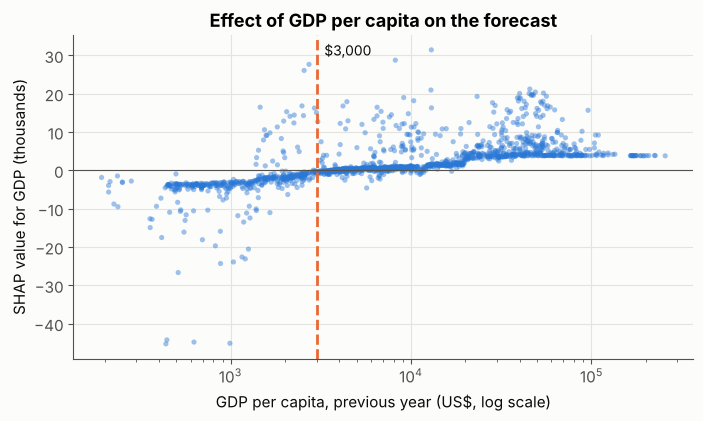

In [15]:
gdp = 10 ** X_test_filled["log_gdp_per_capita_prev"]
gdp_shap = shap_values[:, FEATURES.index("log_gdp_per_capita_prev")]

bands = pd.cut(gdp, [0, 1000, 3000, 10000, 30000, np.inf],
               labels=["< $1k", "$1k to 3k", "$3k to 10k", "$10k to 30k", "> $30k"])
print(pd.Series(gdp_shap, index=gdp.index).groupby(bands, observed=True).agg(["median", "count"]).round(0))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(gdp, gdp_shap / 1000, s=14, color=BLUE, alpha=0.45, edgecolors="none")
ax.axvline(3000, color=ORANGE, lw=2, ls="--")
ax.text(3300, ax.get_ylim()[1] * 0.85, "$3,000", color=INK, fontsize=10)
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xscale("log")
ax.set_xlabel("GDP per capita, previous year (US$, log scale)")
ax.set_ylabel("SHAP value for GDP (thousands)")
ax.set_title("Effect of GDP per capita on the forecast")
fig.savefig(FIGURES / "shap_gdp.png")
plt.show()

## 8. What changed from the dissertation version

| Dissertation notebook | This version | Why |
|---|---|---|
| Data sorted by country, then the first 80% of rows used for training | Train on 1997 to 2014, test on 2015 to 2024 | The old split tested on different countries over the same years, so it was not a forecast |
| Gaps filled forwards and then backwards | Forwards only | Backward filling copies future values into the past |
| Indicators from the same year as the target | Indicators from the previous year | Same-year values are not known when you make the forecast |
| Imputer fitted before the split | Imputer and scaler inside each pipeline | Keeps test data out of the fitting |
| Regional aggregates included | Removed | They double count countries |
| Poverty and remittance cost used (90%+ missing) | Left out | Most values would be invented |
| No baseline | Naive last-year forecast | Shows how much the models really add |
| R² of 0.86 reported | Best R² of 0.74 (linear regression), against 0.69 for the naive baseline | The earlier figure came from the flawed split |
| LSTM and SHAP described | SHAP computed here, LSTM not included | Only results this notebook produces are reported |

## 9. Limitations and next steps

- The data file stops at Russia. Re-running with `scripts/download_wdi.py` covers all countries.
- Net migration is a count, so large countries dominate the pooled metrics. Modelling migration per 1,000 people would treat countries more evenly.
- One-year-ahead only. Multi-year forecasts would be harder and more useful for planning.
- Shocks such as COVID-19 and the war in Ukraine are not predictable from these features.